temp.bufr:   0%|          | 0.00/486k [00:00<?, ?B/s]

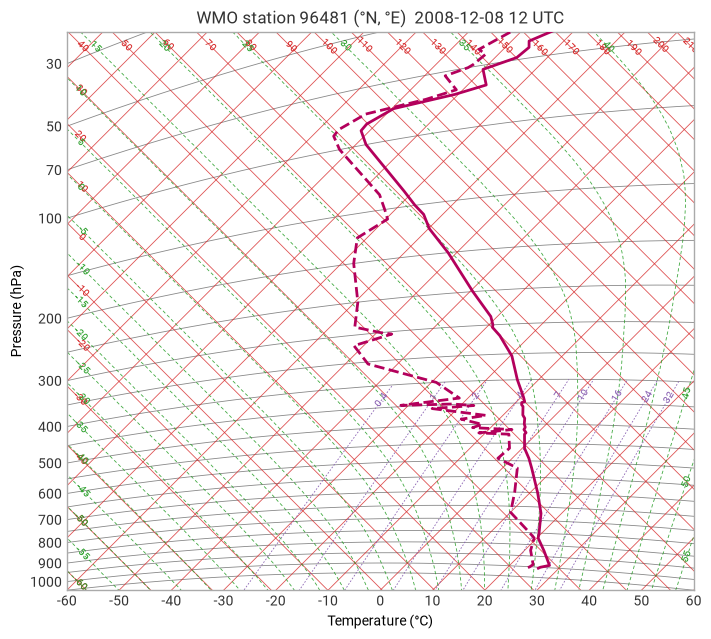

In [7]:
import earthkit.data as ekd
import earthkit.plots as ekp

# read BUFR data: the TEMP reports used by the Metview gallery
data = ekd.from_source(
    "url", "https://sites.ecmwf.int/repository/metview/test-data/gallery/temp.bufr"
)

# thermo_bufr(data=b, station=stations(search_key="ident", ident=96481))
# WMO station 96481 is block 96, station 481
df = data.to_pandas(
    columns=[
        "data_datetime", "latitude", "longitude",
        "pressure", "airTemperature", "dewpointTemperature",
    ],
    filters={"blockNumber": 96, "stationNumber": 481},
)

# Some levels report only wind, so drop the missing values of each profile to
# draw continuous lines (Metview's thermo_*_missing_data_* settings)
t = df.dropna(subset=["airTemperature"])
td = df.dropna(subset=["dewpointTemperature"])

# thermoview(type="tephigram", minimum_temperature=-120, maximum_temperature=35,
#            top_pressure=100)
# earthkit-plots measures the temperature range along the bottom isobar, so the
# default range already contains the sounding; Metview's default bottom
# pressure is 1015 hPa
tephi = ekp.Tephigram()

# mthermo(thermo_temperature_line_colour="purplish_red",
#         thermo_temperature_line_thickness=6, ...)
purplish_red = "#b3005c"
tephi.temperature(
    t["airTemperature"], p=t["pressure"], units="K", p_units="Pa",
    color=purplish_red, linewidth=2,
)
tephi.dewpoint(
    td["dewpointTemperature"], p=td["pressure"], units="K", p_units="Pa",
    color=purplish_red, linewidth=2,
)

station = df.iloc[0]
tephi.title(
    "WMO station 96481 ({latitude:.2f}°N, {longitude:.2f}°E)  "
    f"{station['data_datetime']:%Y-%m-%d %H UTC}"
)

# setoutput(pdf_output(output_name="tephigram_bufr"))
tephi.show()

In [6]:
df

,latitude,longitude,pressure,airTemperature,dewpointTemperature,data_datetime
0,4.27,117.88,100500.0,299.2,297.1,2008-12-08 12:00:00
1,4.27,117.88,100000.0,299.4,297.3,2008-12-08 12:00:00
2,4.27,117.88,98900.0,300.8,297.5,2008-12-08 12:00:00
3,4.27,117.88,96900.0,NaN,NaN,2008-12-08 12:00:00
4,4.27,117.88,92500.0,297.0,294.3,2008-12-08 12:00:00
...,...,...,...,...,...,...
71,4.27,117.88,6580.0,197.7,190.7,2008-12-08 12:00:00
72,4.27,117.88,6340.0,196.5,188.5,2008-12-08 12:00:00
73,4.27,117.88,6270.0,NaN,NaN,2008-12-08 12:00:00
74,4.27,117.88,5980.0,NaN,NaN,2008-12-08 12:00:00
